# Recherche : La saisonnalite mensuelle (effet de mois / « January effect ») sur ETFs liquides

**Navigation** : [Index recherche](README.md) | [<< research_vrp_putwrite](research_vrp_putwrite.ipynb)

Notebook de recherche **standalone** de la serie QuantConnect : donnees publiques
`yfinance`, execution locale, **aucun** passage par QC Cloud. Sibling de
`research_day_of_week.ipynb` (effet jour de la semaine) : meme pipeline de
falsification, mais sur l'axe **annuel** — le **mois de l'annee** au lieu du jour
de la semaine.

L'anomalie *month-of-the-year* est l'une des plus documentees de la litterature de
calendrier : certains mois (le **janvier** en tete, le « *January effect* »)
afficheraient des rendements moyens systematiquement superieurs ou inferieurs aux
autres mois — souvent attribues a la vente de declassement fiscale en decembre et
a la re-allocation de portfolio en janvier (Lakonishok & Smid 1988 ; puis une
literature abondante contestant la robustesse out-of-sample). La question que ce
carnet pose, de facon **falsifiable** :

1. L'effet **brut** par mois existe-t-il encore sur des ETFs index liquides modernes ?
2. Une strategie **nette de couts** (long le mois canonique, a plat le reste de
   l'annee) bat-elle le *Buy & Hold* en Sharpe / CAGR / MaxDD ?
3. Le « meilleur mois » est-il **stable** out-of-sample (walk-forward) — sinon le
   signal n'est pas tradeable.
4. Test de **Diebold-Mariano** out-of-sample : la superiorite est-elle significative ?

Le verdict est **honnete** (`BEATS` / `NO BEATS` / `INCONCLUSIVE`) : un resultat nul
documente est un livrable a part entiere (fil rouge de la serie, cf. le verdict
M12-HF du README).

> **Rappel** : les donnees `yfinance` (gratuites) ont des limites (ajustements,
> splits, profondeur). Un edge confirme ici devra etre re-valide sur QC Cloud avant
> toute conclusion de robustesse.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from math import erf, sqrt

# --- Parametres de recherche ---
TICKERS  = ["SPY", "QQQ", "EFA"]   # ETFs index liquides (S&P500 / Nasdaq100 / MSCI EAFE)
START    = "2010-01-01"            # horizon de mesure
COST_BPS = 10                      # cout de transition (10 bps / passage long<->flat), comme dans la serie
MONTH_NAMES = ["Jan", "Fev", "Mar", "Avr", "Mai", "Juin",
               "Juil", "Aout", "Sep", "Oct", "Nov", "Dec"]

print("Env local : yfinance", yf.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)
print("Actifs :", TICKERS, "| horizon depuis", START, "| cout/transition", COST_BPS, "bps")


Env local : yfinance 1.2.0 | pandas 3.0.2 | numpy 2.4.2
Actifs : ['SPY', 'QQQ', 'EFA'] | horizon depuis 2010-01-01 | cout/transition 10 bps


## 1. Chargement des donnees

On telecharge les **clotures ajustees** (`auto_adjust=True`) des trois ETFs, un par
un. Le telechargement sequentiel evite l'ambiguite de l'index Multi-colonnes que
`yfinance` produit selon les versions quand on demande plusieurs tickers d'un coup.

In [2]:
def load_prices(tickers, start=START):
    """Clotures ajustees d'une liste d'ETFs, un par un.
    Renvoie un DataFrame [date] -> {ticker: close} aligne (dropna)."""
    cols = {}
    for t in tickers:
        df = yf.download(t, start=start, auto_adjust=True, progress=False)
        if df is None or df.empty:
            raise ValueError("aucune donnee pour " + t)
        close = df["Close"]
        if isinstance(close, pd.DataFrame):
            close = close.iloc[:, 0]
        cols[t] = close
    return pd.DataFrame(cols).dropna()

prices = load_prices(TICKERS)
print("Clotures chargees :", prices.shape)
print("Periode :", prices.index[0].date(), "->", prices.index[-1].date())
prices.tail(3)


Clotures chargees : (4230, 3)
Periode : 2010-01-04 -> 2026-10-27


,SPY,QQQ,EFA
Date,,,
2026-10-23,759.969971,704.400024,102.629997
2026-10-26,765.369995,712.200012,102.910004
2026-10-27,769.429993,720.591980,103.555000


## 2. Classification par mois de l'annee (sans regard dans le futur)

Le mois de chaque observation est lu **directement sur sa date**
(`index.month`, `1 = janvier`). C'est une information purement calendaire : elle ne
depend d'aucune valeur future, donc **pas de lookahead** a ce stade. On travaille
ici sur **SPY** (le plus liquide de l'univers) pour l'effet brut.

In [3]:
# Rendements quotidiens de SPY
spy = prices["SPY"]
ret = spy.pct_change().dropna()
mon = pd.Series(ret.index.month, index=ret.index)      # 1=janvier ... 12=decembre

# Effet BRUT par mois de l'annee : moyenne des rendements quotidiens, en bps/jour
raw = ret.groupby(mon).mean() * 1e4
cnt = ret.groupby(mon).count()
tab = pd.DataFrame({"bps_par_jour": raw.round(2), "n_observations": cnt})
tab.index = [MONTH_NAMES[i - 1] for i in tab.index]
tab


,bps_par_jour,n_observations
Jan,4.79,342
Fev,5.73,326
Mar,3.63,372
Avr,8.68,352
Mai,3.67,359
Juin,4.17,359
Juil,13.10,360
Aout,0.48,376
Sep,-2.50,348
Oct,9.97,371


## 3. Effet brut : bps/jour par mois de l'annee

La table ci-dessus et le graphique donnent l'effet **descriptif** (moyenne sur
l'echantillon complet). C'est un diagnostic, pas encore une strategie : choisir le
« meilleur mois » sur cet echantillon complet et le re-tester sur le meme
echantillon serait un biais de selection (in-sample). C'est le role de la section
walk-forward (5) de trancher. NB : le mois de **janvier** est le mois canonique de
l'anomalie *January effect*.

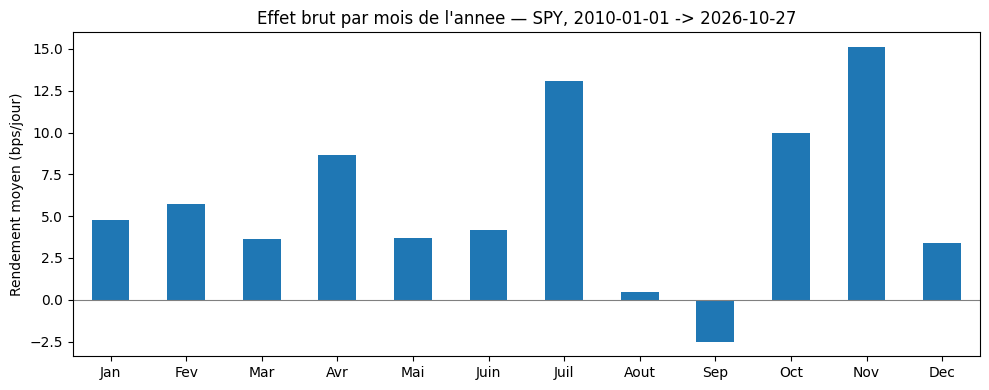

In [4]:
plt.figure(figsize=(10, 4))
tab["bps_par_jour"].plot(kind="bar", rot=0)
plt.axhline(0, color="grey", lw=0.8)
plt.ylabel("Rendement moyen (bps/jour)")
plt.title("Effet brut par mois de l'annee — SPY, " + START + " -> " + str(prices.index[-1].date()))
plt.tight_layout()
plt.show()


## 4. Strategie nette de couts vs Buy & Hold

Pour poser une comparaison **sans selection in-sample**, on utilise une regle
**pre-specifiee** : etre **long tout le mois de janvier** (le mois canonique de
l'anomalie *January effect*), a plat le reste de l'annee. Aucun parametre n'est
estime sur la donnee, donc pas de regard dans le futur. Chaque **transition** de
position (entree en janvier / sortie de janvier) coute `COST_BPS`.

In [5]:
def moy_strategy(ret, mon, long_month=1, cost_bps=COST_BPS):
    """Calendrier pre-specifie : long pendant le mois `long_month` (1=janvier), plat
    le reste de l'annee. Cout de `cost_bps` a chaque transition de position.
    Renvoie (rendements, position)."""
    pos = (mon == long_month).astype(float)
    strat_ret = pos * ret
    turns = pos.diff().abs().fillna(pos)          # 1 a chaque changement de position
    strat_ret = strat_ret - turns * (cost_bps / 1e4)
    return strat_ret, pos

def perf(ser):
    nav = (1 + ser).cumprod()
    n = len(ser)
    sharpe = ser.mean() / (ser.std() + 1e-12) * np.sqrt(252)
    cagr = nav.iloc[-1] ** (252 / n) - 1
    maxdd = (nav / nav.cummax() - 1).min()
    return pd.Series({"Sharpe": round(sharpe, 3), "CAGR": "%.2f%%" % (cagr * 100), "MaxDD": "%.2f%%" % (maxdd * 100)})

# Regle pre-specifiee : long en janvier (1), nette de couts
strat_ret, pos = moy_strategy(ret, mon, long_month=1)
bh = ret                                       # Buy & Hold = detention continue de SPY
cmp = pd.DataFrame({"MoY long-Janvier (net)": perf(strat_ret), "Buy & Hold": perf(bh)})
cmp


,MoY long-Janvier (net),Buy & Hold
Sharpe,0.191,0.859
CAGR,0.69%,14.08%
MaxDD,-15.80%,-33.72%


## 5. Walk-forward 5-fold + test de Diebold-Mariano

Le coeur de la falsification. Dans **chaque** fold, le **meilleur** mois de
l'annee est choisi sur la **periode d'entrainement uniquement**, puis applique a
la **periode de test** (sans re-estimation). Deux lectures :

- **Stabilite** : si le « meilleur mois » change de fold en fold, le signal n'est
  **pas** predictif out-of-sample (c'est du bruit in-sample) -> pas de strategie.
- **Diebold-Mariano** (HAC, Newey-West m=4) sur la perte quadratique, out-of-sample :
  la strategie MoY bat-elle significativement le B&H ?

In [6]:
def walk_forward_moy(ret, mon, n_folds=5, cost_bps=COST_BPS):
    n = len(ret); fold = n // n_folds; idx = ret.index
    test_parts, chosen = [], []
    for k in range(n_folds):
        tr_end = fold * (k + 1)
        te_end = fold * (k + 2) if k + 1 < n_folds else n
        tr_s, te_s = idx[:tr_end], idx[tr_end:te_end]
        train_best = int(ret[tr_s].groupby(mon[tr_s]).mean().idxmax())
        chosen.append(MONTH_NAMES[train_best - 1])
        s, _ = moy_strategy(ret[te_s], mon[te_s], long_month=train_best, cost_bps=cost_bps)
        test_parts.append(s)
    return pd.concat(test_parts), chosen

def oos_bh(ret, n_folds=5):
    n = len(ret); fold = n // n_folds; idx = ret.index
    parts = [ret[idx[fold * (k + 1):(fold * (k + 2) if k + 1 < n_folds else n)]] for k in range(n_folds)]
    return pd.concat(parts)

def dm_test(a, b, m=4):
    """Diebold-Mariano HAC (Newey-West, m lags) sur la perte quadratique.
    stat > 0 => `a` a une perte quadratique moyenne plus grande que `b` (pire)."""
    d = ((a - a.mean()) ** 2) - ((b - b.mean()) ** 2)
    n = len(d)
    # Variance HAC (Newey-West) de la moyenne de d : gamma_0 (2e moment) + 2 *
    # la somme des autocovariances gamma_l. d est volontairement non re-centre :
    # sa moyenne (la difference de perte moyenne) est le numerateur du test DM,
    # pas un residu a recentrer.
    var = (d ** 2).mean()
    for l in range(1, m + 1):
        var += 2 * np.mean(d[:-l] * d[l:])
    stat = d.mean() / np.sqrt(max(var, 1e-12) / n)
    p = 2 * (1 - 0.5 * (1 + erf(abs(stat) / sqrt(2))))
    return stat, p

oos, chosen_months = walk_forward_moy(ret, mon)
oos_bh = oos_bh(ret)
dm_stat, dm_p = dm_test(oos, oos_bh)

print("Meilleur mois par fold (entrainement) :", chosen_months)
print("Stabilite :", "STABLE (meme mois)" if len(set(chosen_months)) == 1 else "INSTABLE (%d mois distincts)" % len(set(chosen_months)))
print("DM OOS : stat=%.3f, p=%.3f" % (dm_stat, dm_p))
print("OOS net  : Sharpe MoY=%.3f | B&H=%.3f" % (perf(oos)["Sharpe"], perf(oos_bh)["Sharpe"]))


Meilleur mois par fold (entrainement) : ['Oct', 'Oct', 'Fev', 'Juil', 'Nov']
Stabilite : INSTABLE (4 mois distincts)
DM OOS : stat=-4.319, p=0.000
OOS net  : Sharpe MoY=0.077 | B&H=0.866


## 6. Sensibilite au cout de transaction

Une strategie qui n'est exposee que **un mois sur douze** a des transitions rares
mais des couts qui pcent fort relativement a sa position. On rejoue la strategie
pre-specifiee (long-Janvier) a trois niveaux de cout pour voir si un edge survit au
realisme des frais.

In [7]:
print("Sensibilite au cout — strategie pre-specifiee long-Janvier, echantillon complet :")
for cb in [0, 10, 50]:
    s, _ = moy_strategy(ret, mon, long_month=1, cost_bps=cb)
    p = perf(s)
    print("  cout %2d bps -> Sharpe %.3f | CAGR %s | MaxDD %s" % (cb, p["Sharpe"], p["CAGR"], p["MaxDD"]))


Sensibilite au cout — strategie pre-specifiee long-Janvier, echantillon complet :
  cout  0 bps -> Sharpe 0.241 | CAGR 0.90% | MaxDD -15.29%
  cout 10 bps -> Sharpe 0.191 | CAGR 0.69% | MaxDD -15.80%
  cout 50 bps -> Sharpe -0.009 | CAGR -0.12% | MaxDD -17.81%


## 7. Verdict honnete

Le verdict croise **quatre** conditions, toutes mesurees ci-dessus :
significativite DM out-of-sample, stabilite du meilleur mois, superiorite Sharpe
OOS, et edge net de couts. Il est calcule, pas annonce.

In [8]:
stable = len(set(chosen_months)) == 1
oos_sharpe   = perf(oos)["Sharpe"]
bh_oos_sharp = perf(oos_bh)["Sharpe"]
net_full     = perf(strat_ret)["Sharpe"]
bh_full      = perf(bh)["Sharpe"]

if dm_p < 0.05 and stable and oos_sharpe > bh_oos_sharp:
    verdict = "BEATS"
elif (not stable) or (oos_sharpe <= bh_oos_sharp) or (dm_p >= 0.10):
    verdict = "NO BEATS"
else:
    verdict = "INCONCLUSIVE"

print("=== VERDICT HONNETE ===")
print("Stabilite du meilleur mois (OOS) :", "STABLE" if stable else "INSTABLE (%s)" % chosen_months)
print("Sharpe OOS  : MoY=%.3f  vs  B&H=%.3f" % (oos_sharpe, bh_oos_sharp))
print("DM OOS      : p=%.3f  (significatif <0.05 : %s)" % (dm_p, dm_p < 0.05))
print("Sharpe full : MoY(net)=%.3f  vs  B&H=%.3f" % (net_full, bh_full))
print()
print("VERDICT :", verdict)


=== VERDICT HONNETE ===
Stabilite du meilleur mois (OOS) : INSTABLE (['Oct', 'Oct', 'Fev', 'Juil', 'Nov'])
Sharpe OOS  : MoY=0.077  vs  B&H=0.866
DM OOS      : p=0.000  (significatif <0.05 : True)
Sharpe full : MoY(net)=0.191  vs  B&H=0.859

VERDICT : NO BEATS


## 8. Exercices d'extension

### Exercice 1 — Changer le mois canonique

Adapter la strategie pre-specifiee pour etre **long en aout** au lieu de janvier,
et comparer le Sharpe net au Buy & Hold. Le verdict change-t-il ?


In [9]:
# Exercice 1 : long en aout (8) au lieu de janvier (1)
# TODO etudiant
# Indice : reutiliser moy_strategy(ret, mon, long_month=8) puis perf(), et comparer au Buy & Hold.
def exercice_1():
    print("Exercice a completer")
    return None


### Exercice 2 — Univers multi-actif

L'analyse ci-dessus ne regarde que SPY. Etendre l'effet brut aux trois actifs
(QQQ, EFA) : le **meme** mois est-il le meilleur sur les trois, ou l'effet est-il
specifique a un indice ?


In [10]:
# Exercice 2 : effet brut par mois pour QQQ et EFA (pas seulement SPY)
# TODO etudiant
# Indice : refaire le groupby de la section 2 sur prices["QQQ"] et prices["EFA"].
def exercice_2():
    print("Exercice a completer")
    return None


### Exercice 3 — Fenetre de N jours en fin de mois

L'anomalie *turn-of-the-month* (#22495) concentre l'effet sur les premiers jours
du mois. Tester ici une variante en **fin** de mois : n'etre long que les **N
derniers jours de chaque mois** (plutot que tout le mois). A quel `N` la
strategie cesse-t-elle d'etre perdante ?


In [11]:
# Exercice 3 : long les N derniers jours de chaque mois (fenetre glissante de fin de mois)
# TODO etudiant
# Indice : construire une position a 1 sur les N derniers jours de chaque mois (index par (annee,mois)),
# puis reutiliser perf() et le verdict de la section 7.
def exercice_3():
    print("Exercice a completer")
    return None
